# Phase 9 — Transformer System Identification

**Goal:** treat a Transformer locally as a nonlinear, depth-varying dynamical system and measure analogues of:

- impulse response;
- step response;
- frequency response;
- perturbation gain;
- stability / finite-depth Lyapunov growth;
- depth time constant \(\tau\).

This notebook is a **new phase**, not a replacement for Phase 7. Phase 7 asks *which sites are causally useful*; Phase 9 asks *how perturbations propagate through depth and token position*.

## Local dynamical-system view

For a residual Transformer,

\[
h_{\ell+1}=F_\ell(h_\ell),
\]

and around a fixed prompt / trajectory \(h_\ell^\*\),

\[
\delta h_{\ell+1}\approx J_\ell\,\delta h_\ell,
\qquad
J_\ell=\frac{\partial F_\ell}{\partial h_\ell}\bigg|_{h_\ell^\*}.
\]

This is generally **nonlinear and layer-varying**, so the classical LTI transfer-function language is only a local approximation.

We therefore estimate **empirical, prompt-conditioned responses** rather than claiming a global LTI model.

## Experimental hypotheses

**H9.1 — Stability:** for most prompts and small perturbations, downstream perturbation gain remains bounded.

**H9.2 — Depth constant:** where perturbation amplitude approximately decays exponentially,

\[
r(\ell)\approx A\,e^{-(\ell-\ell_0)/\tau},
\]

a finite characteristic depth \(\tau\) exists.

**H9.3 — Frequency selectivity:** sinusoidal perturbations across token positions produce non-flat, prompt-conditioned gain spectra.

**H9.4 — Causal connection to Phase 7:** sites/pairs with high Phase-7 causal recovery may show distinctive perturbation gain, persistence, or spectral selectivity.

In [1]:
import os
import math
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "EleutherAI/pythia-160m"
SEED = 20260914
EPS = 1e-3
N_PROMPTS = 8

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if DEVICE == "cuda":
    DTYPE = torch.float16
else:
    DTYPE = torch.float32

print("device:", DEVICE)

C:\Users\Mauro\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu


In [2]:
torch.manual_seed(SEED)
np.random.seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
)
model.to(DEVICE)
model.eval()

layers = model.gpt_neox.layers
N_LAYERS = len(layers)
HIDDEN = model.config.hidden_size

print("layers:", N_LAYERS)
print("hidden:", HIDDEN)

layers: 12
hidden: 768


## Prompt source

If the Phase-7 holdout manifest exists, we reuse its prompts so the dynamical measurements remain tied to the same experimental domain.

Otherwise the notebook uses a small fallback list only as a smoke test.

In [3]:
MANIFEST_CANDIDATES = [
    "phase7_holdout_manifest.csv",
    "phase7_discovery_manifest_final.csv",
]

manifest = None
for path in MANIFEST_CANDIDATES:
    if os.path.exists(path):
        manifest = pd.read_csv(path)
        print("using:", path)
        break

if manifest is not None and "prompt" in manifest.columns:
    PROMPTS = manifest["prompt"].dropna().astype(str).head(N_PROMPTS).tolist()
else:
    PROMPTS = [
        "The capital of France is",
        "The largest planet in the Solar System is",
        "Water freezes at a temperature of",
        "The author of Hamlet was",
    ]
    print("WARNING: Phase-7 manifest not found; using fallback smoke-test prompts.")

print("n prompts:", len(PROMPTS))

n prompts: 4


## Measurement convention

For each prompt, the scalar readout is the **baseline top-next-token logit**.

This is intentional: it gives a reproducible scalar output \(y\) without requiring a task-specific target label.

For a perturbation \(\delta\),

\[
G = \frac{\Delta y}{\|\delta\|}
\]

is a local empirical gain.

We also track hidden-state perturbation norms, which are independent of the scalar readout choice.

In [4]:
@torch.inference_mode()
def baseline_run(prompt):
    enc = tokenizer(prompt, return_tensors="pt")
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    out = model(**enc, output_hidden_states=True)
    logits = out.logits[:, -1, :]
    target_id = int(torch.argmax(logits, dim=-1).item())
    y = float(logits[0, target_id].detach().float().cpu())
    hs = [h.detach().float().cpu() for h in out.hidden_states]
    return enc, target_id, y, hs

def unit_direction(dim, seed):
    g = torch.Generator(device="cpu")
    g.manual_seed(int(seed))
    v = torch.randn(dim, generator=g)
    v = v / (v.norm() + 1e-12)
    return v

# A. Impulse response through depth

An **impulse** is a small perturbation applied to one token at the input of one layer:

\[
h_{\ell_0}(p_0)
\leftarrow
h_{\ell_0}(p_0)+\epsilon v.
\]

We then observe

\[
r(\ell)=
\frac{\|\delta h_\ell\|_2}{\epsilon}.
\]

This is the closest analogue of an impulse response for a local nonlinear Transformer trajectory.

In [5]:
def run_with_layer_impulse(prompt, layer0, token_pos=-1, eps=EPS, seed=SEED):
    enc, target_id, y0, hs0 = baseline_run(prompt)
    direction = unit_direction(HIDDEN, seed).to(DEVICE, dtype=next(model.parameters()).dtype)

    def hook(module, args):
        h = args[0].clone()
        p = token_pos if token_pos >= 0 else h.shape[1] + token_pos
        h[:, p, :] = h[:, p, :] + eps * direction
        return (h,) + tuple(args[1:])

    handle = layers[layer0].register_forward_pre_hook(hook)
    try:
        with torch.inference_mode():
            out = model(**enc, output_hidden_states=True)
    finally:
        handle.remove()

    y1 = float(out.logits[0, -1, target_id].detach().float().cpu())
    hs1 = [h.detach().float().cpu() for h in out.hidden_states]

    rows = []
    for hidx, (a, b) in enumerate(zip(hs0, hs1)):
        d = b - a
        total = float(d.norm().item() / eps)
        token = float(d[:, token_pos, :].norm().item() / eps)
        rows.append({
            "hidden_index": hidx,
            "layer_equivalent": hidx - 1,
            "gain_total": total,
            "gain_probe_token": token,
        })

    return pd.DataFrame(rows), {
        "target_id": target_id,
        "baseline_logit": y0,
        "perturbed_logit": y1,
        "output_gain": (y1 - y0) / eps,
    }

In [6]:
IMPULSE_LAYER = max(0, N_LAYERS // 3)

impulse_rows = []

for pi, prompt in enumerate(PROMPTS):
    resp, meta = run_with_layer_impulse(
        prompt,
        layer0=IMPULSE_LAYER,
        token_pos=-1,
        eps=EPS,
        seed=SEED + pi,
    )
    resp["prompt_id"] = pi
    resp["prompt"] = prompt
    resp["impulse_layer"] = IMPULSE_LAYER
    resp["output_gain"] = meta["output_gain"]
    impulse_rows.append(resp)

impulse_df = pd.concat(impulse_rows, ignore_index=True)
display(impulse_df.head())

impulse_df.to_csv("phase9_impulse_response.csv", index=False)

,hidden_index,layer_equivalent,gain_total,gain_probe_token,prompt_id,prompt,impulse_layer,output_gain
0,0,-1,0.0,0.0,0,The capital of France is,4,-0.061035
1,1,0,0.0,0.0,0,The capital of France is,4,-0.061035
2,2,1,0.0,0.0,0,The capital of France is,4,-0.061035
3,3,2,0.0,0.0,0,The capital of France is,4,-0.061035
4,4,3,0.0,0.0,0,The capital of France is,4,-0.061035


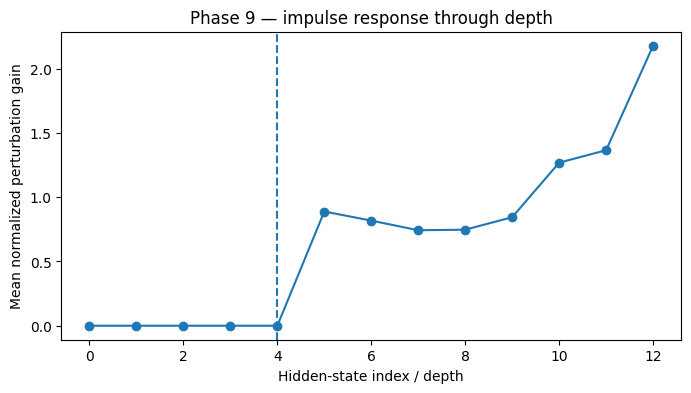

In [7]:
summary_impulse = (
    impulse_df
    .groupby("hidden_index")
    .agg(
        mean_gain=("gain_probe_token", "mean"),
        std_gain=("gain_probe_token", "std"),
        n=("prompt_id", "nunique"),
    )
    .reset_index()
)

plt.figure(figsize=(8,4))
plt.plot(summary_impulse["hidden_index"], summary_impulse["mean_gain"], marker="o")
plt.axvline(IMPULSE_LAYER, linestyle="--")
plt.xlabel("Hidden-state index / depth")
plt.ylabel("Mean normalized perturbation gain")
plt.title("Phase 9 — impulse response through depth")
plt.show()

## Stability and finite-depth Lyapunov growth

For a local perturbation,

\[
\lambda_{\mathrm{eff}}
=
\frac{1}{\Delta \ell}
\log\frac{r(\ell_2)}{r(\ell_1)}.
\]

Interpretation:

- \(\lambda_{\mathrm{eff}}<0\): local contraction;
- \(\lambda_{\mathrm{eff}}\approx0\): neutral persistence;
- \(\lambda_{\mathrm{eff}}>0\): local amplification.

This is **not** a global Lyapunov exponent of the whole model. It is a finite-depth, trajectory-conditioned diagnostic.

In [8]:
def fit_depth_constant(df_one, start_hidden_index):
    d = df_one[df_one["hidden_index"] >= start_hidden_index].copy()
    r = d["gain_probe_token"].to_numpy(dtype=float)
    x = d["hidden_index"].to_numpy(dtype=float)

    ok = np.isfinite(r) & (r > 1e-12)
    r = r[ok]
    x = x[ok]

    if len(r) < 3:
        return {
            "lambda_eff": np.nan,
            "tau_layers": np.nan,
            "fit_r2": np.nan,
        }

    z = np.log(r)
    slope, intercept = np.polyfit(x, z, 1)
    pred = slope * x + intercept

    ss_res = np.sum((z - pred) ** 2)
    ss_tot = np.sum((z - np.mean(z)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    tau = -1.0 / slope if slope < 0 else np.inf

    return {
        "lambda_eff": float(slope),
        "tau_layers": float(tau),
        "fit_r2": float(r2),
    }

stability_rows = []

for prompt_id, d in impulse_df.groupby("prompt_id"):
    fit = fit_depth_constant(
        d,
        start_hidden_index=IMPULSE_LAYER + 1,
    )
    stability_rows.append({
        "prompt_id": prompt_id,
        **fit,
    })

stability_df = pd.DataFrame(stability_rows)
display(stability_df)
stability_df.to_csv("phase9_stability_time_constants.csv", index=False)

,prompt_id,lambda_eff,tau_layers,fit_r2
0,0,0.126194,inf,0.539819
1,1,0.133411,inf,0.578668
2,2,0.161988,inf,0.687353
3,3,0.049262,inf,0.361357


# B. Step response through depth

A depth-step applies the same small forcing at every layer from \(\ell_0\) onward:

\[
u_\ell =
\begin{cases}
0, & \ell<\ell_0\\
\epsilon v, & \ell\ge\ell_0.
\end{cases}
\]

This lets us measure analogues of:

- rise across depth;
- overshoot;
- settling;
- steady-depth gain.

Unlike physical time, the independent variable here is **network depth**.

In [9]:
def run_with_depth_step(prompt, layer0, token_pos=-1, eps=EPS, seed=SEED):
    enc, target_id, y0, hs0 = baseline_run(prompt)
    direction = unit_direction(HIDDEN, seed).to(DEVICE, dtype=next(model.parameters()).dtype)

    handles = []

    def make_hook():
        def hook(module, args):
            h = args[0].clone()
            p = token_pos if token_pos >= 0 else h.shape[1] + token_pos
            h[:, p, :] = h[:, p, :] + eps * direction
            return (h,) + tuple(args[1:])
        return hook

    for li in range(layer0, N_LAYERS):
        handles.append(layers[li].register_forward_pre_hook(make_hook()))

    try:
        with torch.inference_mode():
            out = model(**enc, output_hidden_states=True)
    finally:
        for h in handles:
            h.remove()

    y1 = float(out.logits[0, -1, target_id].detach().float().cpu())
    hs1 = [h.detach().float().cpu() for h in out.hidden_states]

    rows = []
    for hidx, (a, b) in enumerate(zip(hs0, hs1)):
        d = b - a
        rows.append({
            "hidden_index": hidx,
            "layer_equivalent": hidx - 1,
            "gain_total": float(d.norm().item() / eps),
            "gain_probe_token": float(d[:, token_pos, :].norm().item() / eps),
        })

    return pd.DataFrame(rows), {
        "output_gain": (y1 - y0) / eps,
    }

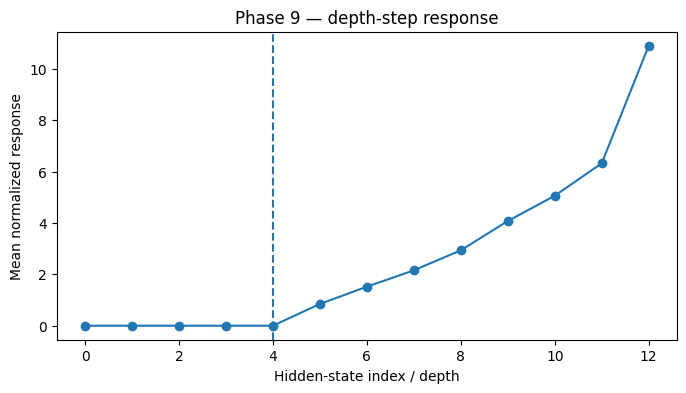

In [10]:
STEP_LAYER = IMPULSE_LAYER

step_rows = []

for pi, prompt in enumerate(PROMPTS):
    resp, meta = run_with_depth_step(
        prompt,
        layer0=STEP_LAYER,
        token_pos=-1,
        eps=EPS,
        seed=SEED + 1000 + pi,
    )
    resp["prompt_id"] = pi
    resp["prompt"] = prompt
    resp["step_layer"] = STEP_LAYER
    resp["output_gain"] = meta["output_gain"]
    step_rows.append(resp)

step_df = pd.concat(step_rows, ignore_index=True)
step_df.to_csv("phase9_step_response.csv", index=False)

summary_step = (
    step_df
    .groupby("hidden_index")
    .agg(mean_gain=("gain_probe_token","mean"))
    .reset_index()
)

plt.figure(figsize=(8,4))
plt.plot(summary_step["hidden_index"], summary_step["mean_gain"], marker="o")
plt.axvline(STEP_LAYER, linestyle="--")
plt.xlabel("Hidden-state index / depth")
plt.ylabel("Mean normalized response")
plt.title("Phase 9 — depth-step response")
plt.show()

# C. Spatial frequency response across token positions

For a prompt with \(N\) tokens, inject a sinusoidal embedding perturbation

\[
\delta e_p^{(c)}
=
\epsilon v\cos(2\pi kp/N),
\]

and a quadrature perturbation

\[
\delta e_p^{(s)}
=
\epsilon v\sin(2\pi kp/N).
\]

For scalar output \(y\),

\[
H(k)
\approx
\frac{\Delta y_c+i\Delta y_s}{\epsilon}.
\]

Then

\[
|H(k)|=\frac{\sqrt{\Delta y_c^2+\Delta y_s^2}}{\epsilon},
\qquad
\phi(k)=\operatorname{atan2}(\Delta y_s,\Delta y_c).
\]

Because the Transformer is not shift-invariant, this is best interpreted as a **prompt-conditioned spatial susceptibility spectrum**, not a universal transfer function.

In [11]:
@torch.inference_mode()
def spatial_frequency_response(prompt, eps=EPS, seed=SEED):
    enc = tokenizer(prompt, return_tensors="pt")
    input_ids = enc["input_ids"].to(DEVICE)
    attention_mask = enc["attention_mask"].to(DEVICE)

    base = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
    )
    target_id = int(torch.argmax(base.logits[:, -1, :], dim=-1).item())
    y0 = float(base.logits[0, -1, target_id].detach().float().cpu())

    embeds = model.gpt_neox.embed_in(input_ids)
    N = embeds.shape[1]

    direction = unit_direction(HIDDEN, seed).to(
        DEVICE,
        dtype=embeds.dtype,
    )

    p = torch.arange(N, device=DEVICE, dtype=embeds.dtype)

    rows = []
    for k in range(N // 2 + 1):
        angle = 2 * math.pi * k * p / max(N, 1)

        cosw = torch.cos(angle)[None, :, None]
        sinw = torch.sin(angle)[None, :, None]

        emb_c = embeds + eps * cosw * direction[None, None, :]
        emb_s = embeds + eps * sinw * direction[None, None, :]

        out_c = model(
            inputs_embeds=emb_c,
            attention_mask=attention_mask,
        )
        out_s = model(
            inputs_embeds=emb_s,
            attention_mask=attention_mask,
        )

        yc = float(out_c.logits[0, -1, target_id].detach().float().cpu())
        ys = float(out_s.logits[0, -1, target_id].detach().float().cpu())

        dc = yc - y0
        ds = ys - y0

        gain = math.sqrt(dc*dc + ds*ds) / eps
        phase = math.atan2(ds, dc)

        rows.append({
            "frequency_index": k,
            "normalized_frequency": k / max(N, 1),
            "gain": gain,
            "phase_rad": phase,
            "delta_cos": dc,
            "delta_sin": ds,
            "n_tokens": N,
        })

    return pd.DataFrame(rows)

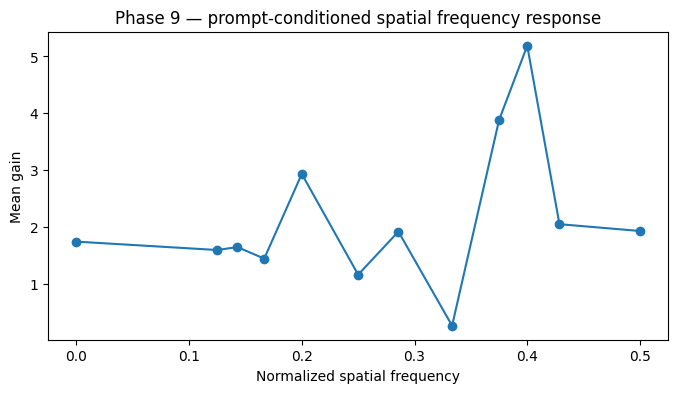

In [12]:
freq_rows = []

for pi, prompt in enumerate(PROMPTS):
    d = spatial_frequency_response(
        prompt,
        eps=EPS,
        seed=SEED + 2000 + pi,
    )
    d["prompt_id"] = pi
    d["prompt"] = prompt
    freq_rows.append(d)

freq_df = pd.concat(freq_rows, ignore_index=True)
freq_df.to_csv("phase9_frequency_response.csv", index=False)

freq_summary = (
    freq_df
    .groupby("normalized_frequency")
    .agg(
        mean_gain=("gain","mean"),
        std_gain=("gain","std"),
        n=("prompt_id","nunique"),
    )
    .reset_index()
)

plt.figure(figsize=(8,4))
plt.plot(
    freq_summary["normalized_frequency"],
    freq_summary["mean_gain"],
    marker="o",
)
plt.xlabel("Normalized spatial frequency")
plt.ylabel("Mean gain")
plt.title("Phase 9 — prompt-conditioned spatial frequency response")
plt.show()

# D. Practical control-style metrics

Useful quantities for future closed-loop / self-improving systems:

### Peak gain
\[
G_{\max}=\max_\ell r(\ell)
\]

Large values indicate perturbation amplification.

### Settling depth
First depth after which the response remains within a tolerance band.

### Effective pole / time constant
If

\[
r_{\ell+1}\approx |\lambda|r_\ell,
\]

then

\[
\tau_{\text{layers}}
=
-\frac{1}{\log|\lambda|}
\quad (|\lambda|<1).
\]

### Closed-loop relevance
If human feedback drives parameter/memory updates,

\[
\theta_{t+1}
=
\theta_t+\eta\,u_t,
\qquad
u_t=C(e_t),
\]

then excessive effective gain can produce oscillation or runaway adaptation.

This is where stability, feedback gain, delay, and multiple time scales become directly relevant to a future co-adaptive human–AI system.

In [13]:
def settling_depth(values, tolerance_fraction=0.05):
    x = np.asarray(values, dtype=float)
    if len(x) == 0 or not np.all(np.isfinite(x)):
        return np.nan
    final = x[-1]
    scale = max(abs(final), 1e-12)
    tol = tolerance_fraction * scale
    for i in range(len(x)):
        if np.all(np.abs(x[i:] - final) <= tol):
            return i
    return np.nan

control_rows = []
for prompt_id, d in step_df.groupby("prompt_id"):
    d = d.sort_values("hidden_index")
    r = d["gain_probe_token"].to_numpy(dtype=float)
    control_rows.append({
        "prompt_id": prompt_id,
        "peak_gain": float(np.nanmax(r)),
        "final_gain": float(r[-1]),
        "settling_hidden_index_5pct": settling_depth(r, 0.05),
    })

control_df = pd.DataFrame(control_rows)
display(control_df)
control_df.to_csv("phase9_control_metrics.csv", index=False)

,prompt_id,peak_gain,final_gain,settling_hidden_index_5pct
0,0,13.624365,13.624365,12
1,1,10.660001,10.660001,12
2,2,9.926400,9.926400,12
3,3,9.387155,9.387155,12


# Interpretation guardrails

1. **Depth is not physical time.** A "time constant" here is measured in layers.
2. A Transformer is not globally LTI. Frequency response is local and prompt-conditioned.
3. A growing perturbation does not automatically mean the model is "unstable" in the control-theory sense; bounded activations, normalization, finite depth, and nonlinear saturation matter.
4. The strongest next step is to connect these diagnostics to Phase-7 causal sites:
   - compare high-AIE vs low-AIE sites;
   - compare high-\(J\) vs low-\(J\) pairs;
   - test whether causal recovery correlates with gain, persistence, or spectral selectivity.
5. If those correlations hold across models, then Phase 9 becomes a genuine bridge between **causal circuits** and **system dynamics**.